In [1]:
import os, pickle
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from bikeroot import viss

folder_path = 'data/testing_4/'
locations = ['Spokane, WA', 'San Francisco, CA', 'Prague', 'Aveiro']

In [2]:
# # def recalc_hv(folder_path):
# #     for filename in os.listdir(folder_path):
# #         if not filename.endswith(('.pickle', '.pkl')):
# #             continue  # skip non-pickle files
# #         file_path = os.path.join(folder_path, filename)
        
# #         # Load the Evaluation object from the pickle file
# #         try:
# #             # Using pandas to load the pickle (can also use plain pickle.load)
# #             eval_obj = pd.read_pickle(file_path)
# #         except Exception as e:
# #             print(f"Could not load {filename}: {e}")
# #             continue

# #         points = eval_obj.hypervolume_ref_point
# #         for i in range(len(points)):
# #             points[i] = points[i] * 5
# #         eval_obj.hypervolume_ref_point = points

# #         for algo_name in eval_obj.results:
# #             for idx in range(len(eval_obj.results[algo_name]['trials'])):
# #                 if eval_obj.results[algo_name]['trials'][idx]['fail'] is None:
# #                     eval_obj.results[algo_name]['trials'][idx]['hypervolume'] = eval_obj.calculate_hypervolume(eval_obj.results[algo_name]['trials'][idx]['costs'])

# import os, pickle
# import numpy as np
# from pymoo.indicators.hv import HV

# FACTOR = 1.10     # 10 % worse than worst point (or pick 5.0 if you prefer)

# def recompute_ref_and_hv(file_path: str, factor: float = FACTOR):
#     with open(file_path, "rb") as f:
#         eval_obj = pickle.load(f)

#     # --- collect ALL costs across all algorithms/trials ---
#     all_costs = []
#     for e in eval_obj.results.values():
#         for tr in e["trials"]:
#             if tr["fail"] is None:              # only successful trials
#                 all_costs.extend(tr["costs"])

#     if not all_costs:          # nothing to do
#         return False

#     F_all = np.array([[c[k] for k in eval_obj.criteria] for c in all_costs], dtype=float)
#     ref_point = F_all.max(axis=0) * factor      # strictly worse than every coord
#     eval_obj.hypervolume_ref_point = ref_point.astype(float)

#     # --- recompute HV for every successful trial ---
#     hv_indicator = HV(ref_point=eval_obj.hypervolume_ref_point)
#     for e in eval_obj.results.values():
#         for tr in e["trials"]:
#             if tr["fail"] is None:
#                 F = np.array([[c[k] for k in eval_obj.criteria] for c in tr["costs"]], dtype=float)
#                 tr["hypervolume"] = hv_indicator.do(F)

#     # save file back (overwrite)
#     with open(file_path, "wb") as f:
#         pickle.dump(eval_obj, f)

#     return True


# def recalc_hv(folder_path: str):
#     for fn in os.listdir(folder_path):
#         if fn.endswith((".pkl", ".pickle")):
#             fp = os.path.join(folder_path, fn)
#             try:
#                 ok = recompute_ref_and_hv(fp)
#                 if ok:
#                     print(f"Updated HV in {fn}")
#                 else:
#                     print(f"No valid trials in {fn}")
#             except Exception as err:
#                 print(f"Failed {fn}: {err}")


In [3]:
# def debug_zero_hv(eval_obj, zero_alg):
#     """Print the rows whose costs exceed the reference point."""
#     ref = eval_obj.hypervolume_ref_point
#     crit = eval_obj.criteria

#     tr   = next(t for t in eval_obj.results[zero_alg]["trials"] if t["fail"] is None)
#     F    = np.array([[c[k] for k in crit] for c in tr["costs"]], float)
#     print(f'path_count: {len(tr["paths"])}')
#     print(f'cost_count: {len(tr["costs"])}')
#     print(tr["costs"])
#     print(ref)
#     print("hv : ", tr["hypervolume"])

#     mask = (F > ref).any(axis=1)      # rows outside the box
#     if mask.any():
#         for i, row in enumerate(F[mask]):
#             print(f"point {i}: {[f'{v:,.3f}' for v in row]}  exceeds  ref {ref}")
#     else:
#         print("No point exceeds the reference -> the set was empty.")

In [4]:
# eval_obj = pd.read_pickle("data/testing_4/aveiro_3294255657_3294255561_eval.pkl")
# # eval_obj = pd.read_pickle("data/testing_4/aveiro_2742209253_1389972309_eval.pkl")
# debug_zero_hv(eval_obj, "linastar_20")


In [5]:
# recalc_hv(folder_path)

In [6]:
folder_path = 'data/testing_4/'
df_pickle_path = 'data/testing_candidates_4/df.pickle'
df = pickle.load(open(df_pickle_path, 'rb')) if os.path.exists(df_pickle_path) else viss.load_evaluation_results(folder_path)
# df = viss.load_evaluation_results(folder_path)
# pickle.dump(df, open('data/testing_candidates_4/df.pickle', 'wb'))

In [7]:
# df.head(300)

In [8]:
# Print hypervolume for each algorithm at each scenario, including lent
cols = ["scenario", "algorithm", "lent", "hypervolume"]
print(df[cols].to_string(index=False))

                                     scenario         algorithm         lent   hypervolume
        aveiro_2742209253_1389972309_eval.pkl          namoa_tc  3069.183667  1.332446e+12
        aveiro_2742209253_1389972309_eval.pkl   hmls_125_16_005  3069.183667  1.313033e+12
        aveiro_2742209253_1389972309_eval.pkl    hmls_125_16_05  3069.183667  1.030848e+12
        aveiro_2742209253_1389972309_eval.pkl ngamobrp_10_50_01  3069.183667  1.331721e+12
        aveiro_2742209253_1389972309_eval.pkl ngamobrp_20_25_01  3069.183667  1.317539e+12
        aveiro_2742209253_1389972309_eval.pkl     nga2_10_50_01  3069.183667  1.331785e+12
        aveiro_2742209253_1389972309_eval.pkl       linastar_20  3069.183667  1.327805e+12
        aveiro_2742209253_1389972309_eval.pkl      linastar_100  3069.183667  1.330654e+12
        aveiro_2742209253_1389972309_eval.pkl    hmls_110_16_01  3069.183667  1.296547e+12
        aveiro_2742209253_1389972309_eval.pkl   linastar_tc_100  3069.183667  1.330654e+12

In [9]:
# pickle.dump(df, open('data/testing_candidates_4/df.pickle', 'wb'))

In [10]:
colors = viss.make_algorithm_color_dict(df)
# viss.plot_runtime_vs_path_length(df, color_dict=colors)

In [11]:
# viss.plot_hypervolume_vs_path_length(df, color_dict=colors)
# viss.plot_ndcount_vs_path_length(df, color_dict=colors)

In [12]:
# overall_tbl = viss.compute_overall_stats(df)         # shows & returns table
# group_tbl   = viss.compute_grouped_stats(df)  


=== hypervolume (median) by dist_group ===
 dist_group         algorithm  median_hypervolume
        500   linastar_tc_100        3.236441e+07
        500          namoa_tc        1.928227e+07
        500   hmls_125_16_005        1.926597e+07
        500      linastar_100        1.926597e+07
        500    hmls_110_16_01        1.895111e+07
        500       linastar_20        1.895111e+07
        500     nga2_10_50_01        1.895111e+07
        500 ngamobrp_10_50_01        1.895111e+07
        500 ngamobrp_20_25_01        1.895111e+07
        500    hmls_125_16_05        1.199491e+07
       1500          namoa_tc        1.310722e+10
       1500     nga2_10_50_01        1.307481e+10
       1500 ngamobrp_10_50_01        1.307481e+10
       1500 ngamobrp_20_25_01        1.307476e+10
       1500   hmls_125_16_005        1.305907e+10
       1500      linastar_100        1.305048e+10
       1500       linastar_20        1.305048e+10
       1500    hmls_110_16_01        1.293548e+10
      

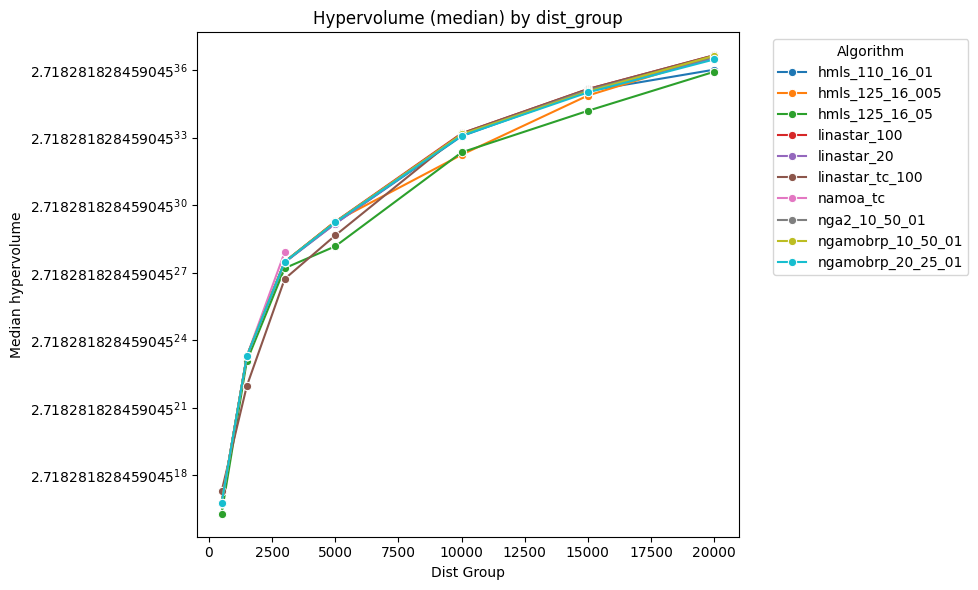

In [13]:
tbl = viss.compute_metric_by_group(df, "hypervolume", agg="median", verbose=True)
ax  = viss.plot_metric_by_group(df, "hypervolume", agg="median", color_dict=colors)
plt.show()


=== time (median) by dist_group ===
 dist_group         algorithm  median_time
        500   linastar_tc_100     8.827432
        500          namoa_tc     4.184495
        500 ngamobrp_20_25_01     3.091049
        500 ngamobrp_10_50_01     2.874689
        500      linastar_100     2.862946
        500     nga2_10_50_01     0.323578
        500    hmls_110_16_01     0.130353
        500       linastar_20     0.030040
        500   hmls_125_16_005     0.008641
        500    hmls_125_16_05     0.004664
       1500   linastar_tc_100    11.690377
       1500          namoa_tc     5.293131
       1500      linastar_100     3.545148
       1500 ngamobrp_10_50_01     3.484925
       1500 ngamobrp_20_25_01     3.128738
       1500    hmls_110_16_01     1.331160
       1500     nga2_10_50_01     1.025785
       1500   hmls_125_16_005     0.170074
       1500       linastar_20     0.086463
       1500    hmls_125_16_05     0.037162
       3000          namoa_tc    20.069396
       3000   lin

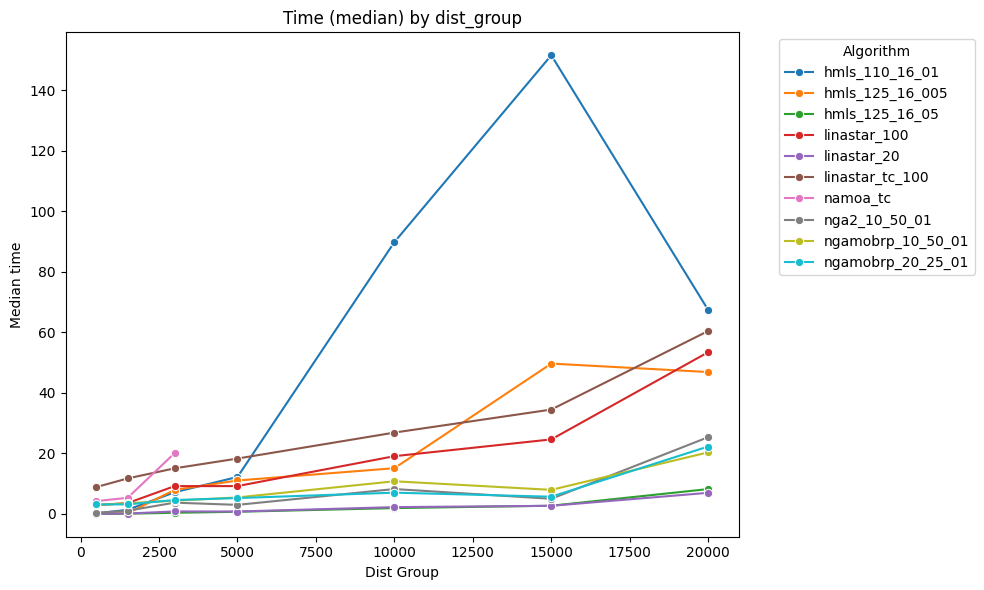

In [14]:
tbl = viss.compute_metric_by_group(df, "time", agg="median", verbose=True)
ax  = viss.plot_metric_by_group(df, "time", agg="median", color_dict=colors)
plt.show()


=== count (median) by dist_group ===
 dist_group         algorithm  median_count
        500   linastar_tc_100           2.5
        500          namoa_tc           2.5
        500   hmls_125_16_005           2.0
        500      linastar_100           2.0
        500    hmls_110_16_01           1.5
        500       linastar_20           1.5
        500     nga2_10_50_01           1.5
        500 ngamobrp_10_50_01           1.5
        500 ngamobrp_20_25_01           1.5
        500    hmls_125_16_05           1.0
       1500          namoa_tc           8.5
       1500     nga2_10_50_01           6.5
       1500 ngamobrp_10_50_01           6.0
       1500 ngamobrp_20_25_01           5.5
       1500   linastar_tc_100           4.0
       1500   hmls_125_16_005           3.5
       1500      linastar_100           3.5
       1500       linastar_20           3.5
       1500    hmls_110_16_01           2.5
       1500    hmls_125_16_05           1.0
       3000          namoa_tc         

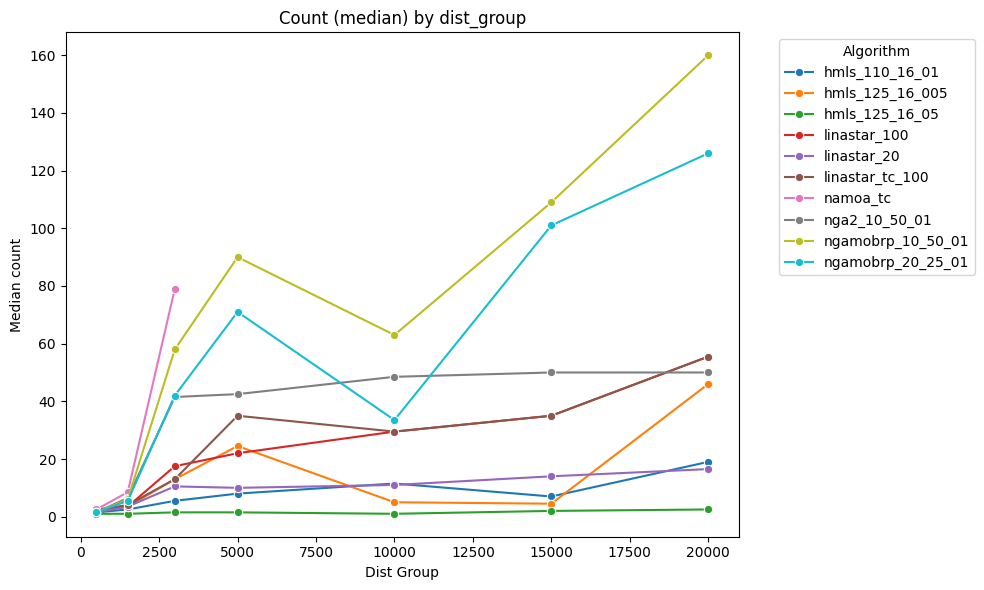

In [15]:
tbl = viss.compute_metric_by_group(df, "count", agg="median", verbose=True)
ax  = viss.plot_metric_by_group(df, "count", agg="median", color_dict=colors)
plt.show()

In [16]:

# df = viss.load_evaluation_results("results_pickles")   # your folder

# 1)  Write the LaTeX median table
# latex_code = viss.save_median_tables_per_dist_group_tex(df)
# print(latex_code)     # inspect / copy if you wish

# # 2)  Get a quick failure overview
# viss.print_failure_summary(df)
viss.print_failed_trials_by_file(df)


=== Failed trials by pickle file ===
• prague_344905901_306618174_eval.pkl  (1 failed rows)
    ↳  namoa_tc
• prague_3676311049_1300523301_eval.pkl  (1 failed rows)
    ↳  hmls_125_16_005
• prague_406383508_1286773192_eval.pkl  (1 failed rows)
    ↳  hmls_125_16_005
• prague_8197519245_2167454315_eval.pkl  (2 failed rows)
    ↳  hmls_110_16_01, hmls_125_16_005
• san_francisco_6708701281_9777791285_eval.pkl  (1 failed rows)
    ↳  namoa_tc
• san_francisco_673040400_4924918588_eval.pkl  (2 failed rows)
    ↳  hmls_110_16_01, hmls_125_16_005
• san_francisco_7231700331_4550837375_eval.pkl  (1 failed rows)
    ↳  hmls_125_16_005
• san_francisco_8071218891_308298975_eval.pkl  (1 failed rows)
    ↳  hmls_125_16_005
• spokane_12146623728_10159619849_eval.pkl  (1 failed rows)
    ↳  namoa_tc
• spokane_51056471_8573490448_eval.pkl  (1 failed rows)
    ↳  hmls_125_16_005


In [17]:
# # for loc in locations:
# #     viss.plot_location_performance(df, loc, colors)
# # After you have `df` in memory
# # viss.save_location_metrics_tex(
# #     df,
# #     filepath="figs/location_metrics.tex",      # any folder you like
# #     metrics=["hypervolume", "time", "count"],  # default – can omit
# #     agg="mean",                                # or "median", "max", …
# # )
# viss.save_raw_tables_by_location_tex(df, out_dir="figs/raw_tables")



In [18]:

# # Plot per-location performance graphs

# for loc in locations:
#     viss.plot_location_performance(df, loc, colors)

# # Compute and display summary table of overall performance
# agg_df = viss.compute_metrics_by_group(df, groupby_cols=['algorithm'], metrics=['hypervolume', 'time', 'count'])
# print(agg_df)

# # Bar charts for aggregate metrics
# viss.plot_overall_bar_chart(df, metric='hypervolume', colors=colors)
# viss.plot_overall_bar_chart(df, metric='time', colors=colors)

# #  Scatter plot of average hypervolume vs runtime
# viss.plot_hypervolume_vs_runtime(df, colors=colors)

# # Combined performance vs distance across all locations
# viss.plot_combined_performance_vs_distance(df, metric='hypervolume', colors=colors)
# viss.plot_combined_performance_vs_distance(df, metric='time', colors=colors)

# # Compare performance on shortest vs longest routes
# # Define short and long distances (e.g., 500 m and 20000 m)
# short_dist = 500
# long_dist = 20000
# short_long_df = viss.compare_short_vs_long(df, short_dist, long_dist, metrics=['hypervolume', 'time'])
# print(short_long_df)
